In [1]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.spatial import distance_matrix
from scipy.spatial import distance
from scipy.optimize import minimize
from scipy.optimize import basinhopping
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
import math
import shutil
import time
from numba import jit
import os
import statistics

In [2]:
##############################################
# To Create your platelet, you can vary the
# dimensions below. The rest of the data initialization
# section of the code does not need to be changed.
##############################################

z_dist = 5.44  #z distance between plateletes for 2 layer platelet system

percent = 0.775  #size percentage of the edge atom hexagon (<1 so the edge atoms have smaller radius)

flat_radius = 5.19  #flat plate radius

hex_radius = 5.19   #hexagon radius

theta = 61 *np.pi/180   #theta of double layer platelet system, in rad

n_rings = 3

x_dist = z_dist/np.tan(theta) #x distance shift of bottom layer based on theta
x_dist
y_dist=x_dist
x_dist

3.015441239903064

In [3]:
def hexa(n_rings,radius):
    #width and height of the hexagon
    w = radius*2/np.sqrt(3)
    h = radius
    N = int(n_rings/2)

    #generate empty arrays
    central_x = []
    central_y = []
    edge_x = []
    edge_y = []

    if (n_rings%2==1):
        print("n_rings must be even number")
    else:
        #top edge atom layer
        edge_x.append(0)
        edge_y.append(0)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #first half of hexagon
        for i in range(N):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0])
            central_y.append(edge_y[0]-h)
            for j in range(N+i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]-0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])

        #second half of hexagon
        for i in range(N-1):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N+(N-i)-1):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0]-h)
            for j in range(N+(N-i)-2):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]+0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N +(N-i)-3):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])
        central_x.append(edge_x[0]+0.75*w)
        central_y.append(edge_y[0]-0.5*h)
        for j in range(N):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        central_x.append(edge_x[0]+1.5*w)
        central_y.append(edge_y[0]-h)
        for j in range(N-1):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        edge_x.append(edge_x[0]+0.75*w)
        edge_y.append(edge_y[0]-1.5*h)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #center of mass back to 0
        edge_x -= np.average(edge_x)
        edge_y -= np.average(edge_y)
        central_x -= np.average(central_x)
        central_y -= np.average(central_y)

        #NEW - MERGE EDGE AND CENTRAL
        central_x = np.concatenate((central_x,edge_x))
        central_y = np.concatenate((central_y,edge_y))

        #NEW - EDGE ATOMS
        edge_x = []
        edge_y = []

        edge_x.append(n_rings*0.75*w+0.5*w)
        edge_y.append(0)

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)

        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]-1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)

    return central_x,central_y,edge_x,edge_y

Total number of atoms, small platelet:  25
Long diameter, small platelet: 23.972 A: 


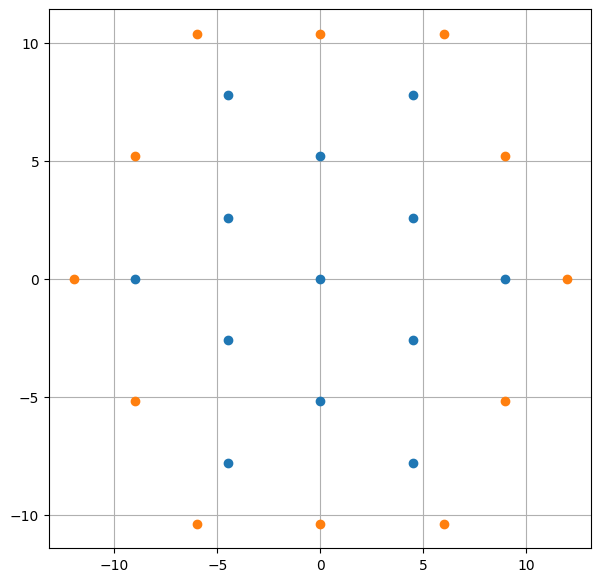

Center of Mass Before Shift: [ 3.55271368e-17 -1.50772062e+00  2.72000000e+00]
New Center of Mass (Should be ~0): [ 3.55271368e-17 -4.08562073e-16  1.08357767e-15]


In [4]:

#create flat plate edge and central atoms for the small platelet
x,y,xx,yy = hexa(2,5.19)

#print total number of atoms
print("Total number of atoms, small platelet: ",len(x)+len(xx))
print("Long diameter, small platelet: %.3f A: " %(max(xx)-min(xx)))

z = np.zeros(len(x))
zz = np.zeros(len(xx))

#put x,y,z data into one array
CentralPlatelet = np.stack((x,y,z),axis=-1)
EdgePlatelet = np.stack((xx,yy,zz),axis=-1)

#plot results
plt.figure(figsize=(7,7))
plt.plot(CentralPlatelet[:,0],CentralPlatelet[:,1],"o")
plt.plot(EdgePlatelet[:,0],EdgePlatelet[:,1],"o")
plt.grid()
plt.show()



#make two platelets
CentralPlatelet2=CentralPlatelet.copy()
CentralPlatelet2[:,2]=CentralPlatelet[:,2]+z_dist
CentralPlatelet2[:,1]=CentralPlatelet[:,1]-y_dist
 
EdgePlatelet2=EdgePlatelet.copy()
EdgePlatelet2[:,2]=EdgePlatelet[:,2]+z_dist
EdgePlatelet2[:,1]=EdgePlatelet[:,1]-y_dist
 
#fit into one array
S_CentralPlate = np.vstack((CentralPlatelet,CentralPlatelet2))
S_EdgePlate = np.vstack((EdgePlatelet,EdgePlatelet2))

all_particles = np.vstack((S_CentralPlate, S_EdgePlate))
center_of_mass = np.mean(all_particles, axis=0)  # Get (x, y, z) center of mass
print("Center of Mass Before Shift:", center_of_mass)

# Shift all coordinates to center COM at (0,0,0)
S_CentralPlate -= center_of_mass
S_EdgePlate -= center_of_mass

# Double-check new COM
new_center_of_mass = np.mean(np.vstack((S_CentralPlate, S_EdgePlate)), axis=0)
print("New Center of Mass (Should be ~0):", new_center_of_mass)






# Distances between edge particles in y-direction

Total number of atoms, small platelet:  25
Long diameter, small platelet: 23.972 A: 
Center of Mass Before Shift: [ 3.55271368e-17 -1.50772062e+00  2.72000000e+00]
New Center of Mass (Should be ~0): [ 3.55271368e-17 -4.08562073e-16  1.08357767e-15]


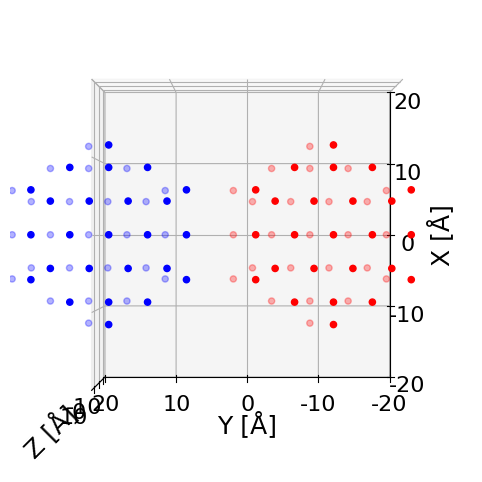

In [7]:

#create flat plate edge and central atoms for the small platelet
x,y,xx,yy = hexa(2,5.19)

#print total number of atoms
print("Total number of atoms, small platelet: ",len(x)+len(xx))
print("Long diameter, small platelet: %.3f A: " %(max(xx)-min(xx)))

z = np.zeros(len(x))
zz = np.zeros(len(xx))

#put x,y,z data into one array
CentralPlatelet = np.stack((x,y,z),axis=-1)
EdgePlatelet = np.stack((xx,yy,zz),axis=-1)

#make two platelets
CentralPlatelet2=CentralPlatelet.copy()
CentralPlatelet2[:,2]=CentralPlatelet[:,2]+z_dist
CentralPlatelet2[:,1]=CentralPlatelet[:,1]-y_dist

EdgePlatelet2=EdgePlatelet.copy()
EdgePlatelet2[:,2]=EdgePlatelet[:,2]+z_dist
EdgePlatelet2[:,1]=EdgePlatelet[:,1]-y_dist

#fit into one array
S_CentralPlate = np.vstack((CentralPlatelet,CentralPlatelet2))
S_EdgePlate = np.vstack((EdgePlatelet,EdgePlatelet2))


all_particles = np.vstack((S_CentralPlate, S_EdgePlate))
center_of_mass = np.mean(all_particles, axis=0)  # Get (x, y, z) center of mass
print("Center of Mass Before Shift:", center_of_mass)

# Shift all coordinates to center COM at (0,0,0)
S_CentralPlate -= center_of_mass
S_EdgePlate -= center_of_mass

# Double-check new COM
new_center_of_mass = np.mean(np.vstack((S_CentralPlate, S_EdgePlate)), axis=0)
print("New Center of Mass (Should be ~0):", new_center_of_mass)



#mirror flat plate data for the large platelet
S_CentralPlateMirr=S_CentralPlate.copy()

S_EdgePlateMirr=S_EdgePlate.copy()

#plot both
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')
ax.scatter(S_CentralPlate[:,0],S_CentralPlate[:,1]-10,S_CentralPlate[:,2], color = 'red', label = "Central Original Platelet")
ax.scatter(S_EdgePlate[:,0],S_EdgePlate[:,1]-10,S_EdgePlate[:,2], color = 'red',label = "Edge Original Platelet")
ax.scatter(S_CentralPlateMirr[:,0],S_CentralPlateMirr[:,1]+20,S_CentralPlateMirr[:,2], color = 'blue',label = "Central Mirrored Platelet")
ax.scatter(S_EdgePlateMirr[:,0],S_EdgePlateMirr[:,1]+20,S_EdgePlateMirr[:,2], color = 'blue',label = "Edge Mirrored Platelet")
ax.set_xlim([-20, 20])
ax.set_ylim([-20, 20])
ax.set_zlim([-15, 15])
ax.set_xticks(list(range(-20,21,10)))
ax.set_xticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_yticks(list(range(-20,21,10)))
ax.set_yticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_zticks(list(range(-10,11,10)))
ax.set_zticklabels(list(range(-10,11,10)),fontsize=16)
ax.set_xlabel('X [Å]',labelpad=12,fontsize=18)
ax.set_ylabel('Y [Å]',labelpad=10,fontsize=18)
ax.set_zlabel('Z [Å]',labelpad=7,fontsize=18)
ax.view_init(elev=90, azim=180)

plt.show()



Total number of atoms, small platelet:  25
Long diameter, small platelet: 23.972 A: 
Center of Mass Before Shift: [ 3.55271368e-17 -1.50772062e+00  2.72000000e+00]
New Center of Mass (Should be ~0): [ 3.55271368e-17 -4.08562073e-16  1.08357767e-15]


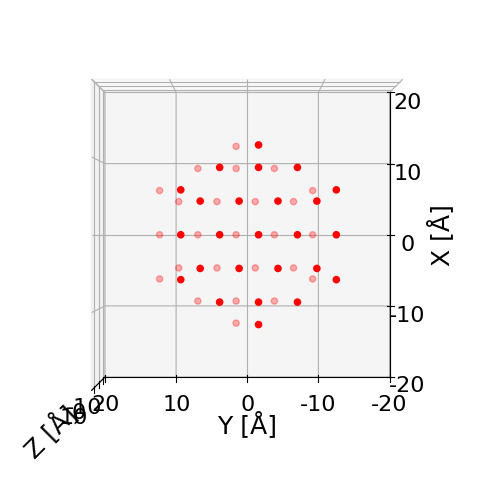

In [8]:
os.chdir('/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/')
f_Stack=np.genfromtxt('distance_edge.out', dtype=float,skip_header=0,skip_footer=0)

z_S=f_Stack[:,0]



x,y,xx,yy = hexa(2,5.19)

#print total number of atoms
print("Total number of atoms, small platelet: ",len(x)+len(xx))
print("Long diameter, small platelet: %.3f A: " %(max(xx)-min(xx)))

z = np.zeros(len(x))
zz = np.zeros(len(xx))

#put x,y,z data into one array
CentralPlatelet = np.stack((x,y,z),axis=-1)
EdgePlatelet = np.stack((xx,yy,zz),axis=-1)

#make two platelets
CentralPlatelet2=CentralPlatelet.copy()
CentralPlatelet2[:,2]=CentralPlatelet[:,2]+z_dist
CentralPlatelet2[:,1]=CentralPlatelet[:,1]-y_dist

EdgePlatelet2=EdgePlatelet.copy()
EdgePlatelet2[:,2]=EdgePlatelet[:,2]+z_dist
EdgePlatelet2[:,1]=EdgePlatelet[:,1]-y_dist

#fit into one array
S_CentralPlate = np.vstack((CentralPlatelet,CentralPlatelet2))
S_EdgePlate = np.vstack((EdgePlatelet,EdgePlatelet2))


all_particles = np.vstack((S_CentralPlate, S_EdgePlate))
center_of_mass = np.mean(all_particles, axis=0)  # Get (x, y, z) center of mass
print("Center of Mass Before Shift:", center_of_mass)

# Shift all coordinates to center COM at (0,0,0)
S_CentralPlate -= center_of_mass
S_EdgePlate -= center_of_mass

# Double-check new COM
new_center_of_mass = np.mean(np.vstack((S_CentralPlate, S_EdgePlate)), axis=0)
print("New Center of Mass (Should be ~0):", new_center_of_mass)



#mirror flat plate data for the large platelet
S_CentralPlateMirr=S_CentralPlate.copy()

S_EdgePlateMirr=S_EdgePlate.copy()

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')
ax.scatter(S_CentralPlate[:,0],S_CentralPlate[:,1],S_CentralPlate[:,2], color = 'red', label = "Central Original Platelet")
ax.scatter(S_EdgePlate[:,0],S_EdgePlate[:,1],S_EdgePlate[:,2], color = 'red',label = "Edge Original Platelet")
# ax.scatter(S_CentralPlateMirr[:,0],S_CentralPlateMirr[:,1]+20,S_CentralPlateMirr[:,2], color = 'blue',label = "Central Mirrored Platelet")
# ax.scatter(S_EdgePlateMirr[:,0],S_EdgePlateMirr[:,1]+20,S_EdgePlateMirr[:,2], color = 'blue',label = "Edge Mirrored Platelet")
ax.set_xlim([-20, 20])
ax.set_ylim([-20, 20])
ax.set_zlim([-15, 15])
ax.set_xticks(list(range(-20,21,10)))
ax.set_xticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_yticks(list(range(-20,21,10)))
ax.set_yticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_zticks(list(range(-10,11,10)))
ax.set_zticklabels(list(range(-10,11,10)),fontsize=16)
ax.set_xlabel('X [Å]',labelpad=12,fontsize=18)
ax.set_ylabel('Y [Å]',labelpad=10,fontsize=18)
ax.set_zlabel('Z [Å]',labelpad=7,fontsize=18)
ax.view_init(elev=90, azim=180)

plt.show()





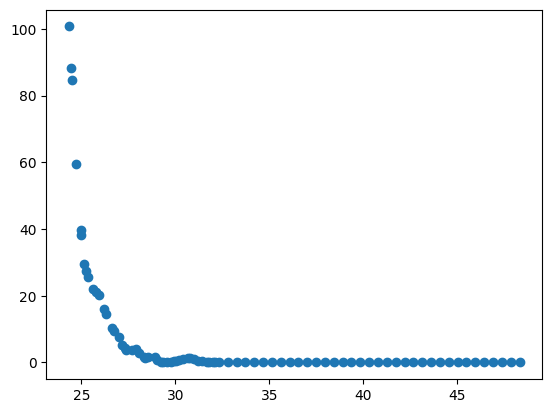

cc
Iteration 0: d-spacing = 24.3223226142457, Kept 323 distances
ec
Iteration 0: d-spacing = 24.3223226142457, Kept 268 distances
ce
Iteration 0: d-spacing = 24.3223226142457, Kept 268 distances
ee
Iteration 0: d-spacing = 24.3223226142457, Kept 246 distances
cc
Iteration 1: d-spacing = 24.454881793517405, Kept 307 distances
ec
Iteration 1: d-spacing = 24.454881793517405, Kept 262 distances
ce
Iteration 1: d-spacing = 24.454881793517405, Kept 262 distances
ee
Iteration 1: d-spacing = 24.454881793517405, Kept 246 distances
cc
Iteration 2: d-spacing = 24.493634649059626, Kept 307 distances
ec
Iteration 2: d-spacing = 24.493634649059626, Kept 262 distances
ce
Iteration 2: d-spacing = 24.493634649059626, Kept 262 distances
ee
Iteration 2: d-spacing = 24.493634649059626, Kept 246 distances
cc
Iteration 3: d-spacing = 24.72150148819528, Kept 307 distances
ec
Iteration 3: d-spacing = 24.72150148819528, Kept 260 distances
ce
Iteration 3: d-spacing = 24.72150148819528, Kept 260 distances
ee
Ite

In [56]:
os.chdir('/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1')
f_Stack=np.genfromtxt('dspacing_PMF.out', dtype=float,skip_header=0,skip_footer=0)
sorted_indices = np.argsort(f_Stack[:, 0])
f_Stack = f_Stack[sorted_indices]
z_S = f_Stack[:, 0]

plt.scatter(f_Stack[:, 0], f_Stack[:, 1])
plt.show()
# S_CentralPlateMirr=S_CentralPlate.copy()

# S_EdgePlateMirr=S_EdgePlate.copy()


cen_dis = {}
ed_cen_dis = {}
ed_dis = {}
cen_ed_dis = {}

for i, spacing in enumerate(z_S):

    Hex_moved_cen = S_CentralPlate.copy()  
    Hex_moved_cen[:, 1] += spacing 
#     plt.scatter(Hex_moved_cen[:, 1],Hex_moved_cen[:, 0])
#     plt.scatter(S_CentralPlate[:, 1],S_CentralPlate[:, 0])
#     plt.show()
    dist_matrix_cc = distance.cdist(S_CentralPlate, Hex_moved_cen)
    final_distances_cc = dist_matrix_cc[dist_matrix_cc <= 25]   
    cen_dis[round(spacing, 5)] = final_distances_cc
    print('cc')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_cc)} distances")

####    
    Hex_moved_ed = S_EdgePlate.copy()  
    Hex_moved_ed[:, 1] += spacing 
    dist_matrix_ec = distance.cdist(S_CentralPlate, Hex_moved_ed)
    final_distances_ec = dist_matrix_ec[dist_matrix_ec <= 25]   
    ed_cen_dis[round(spacing, 5)] = final_distances_ec
    print('ec')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ec)} distances")

####    
    Hex_moved_cen = S_CentralPlate.copy()  
    Hex_moved_cen[:, 1] += spacing 
    dist_matrix_ce = distance.cdist(S_EdgePlate, Hex_moved_cen)
    final_distances_ce = dist_matrix_ce[dist_matrix_ce <= 25]   
    cen_ed_dis[round(spacing, 5)] = final_distances_ce
    print('ce')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ce)} distances")

####    
    
    
    
    Hex_moved_ed = S_EdgePlate.copy()  
    Hex_moved_ed[:, 1] += spacing 
    dist_matrix_ee = distance.cdist(S_EdgePlate, Hex_moved_ed)
    final_distances_ee = dist_matrix_ee[dist_matrix_ee <= 25]   
    ed_dis[round(spacing, 5)] = final_distances_ee
    print('ee')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ee)} distances")
    
    
    
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_CC.npy"
np.save(output_file_npy, cen_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_EC.npy"
np.save(output_file_npy, ed_cen_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")

    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_CE.npy"
np.save(output_file_npy, cen_ed_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_EE.npy"
np.save(output_file_npy, ed_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    

    